# Telecom Customer Churn Propensity Model
Predict which subscribers are likely to churn so a retention team can prioritize outreach.

**Data:** 3,150 subscribers of a telecom operator. Usage features are aggregated over the first 9 months;
the churn label is the customer's status at month 12.

**Workflow:** data cleaning → EDA → feature engineering → train / validation / test split →
model comparison with cross-validation → hyperparameter tuning → threshold selection on validation →
a single final evaluation on the held-out test set → risk-by-value segmentation for retention planning.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:.4f}".format)
os.makedirs("../images", exist_ok=True)
RANDOM_STATE = 42

## 1. Load and Clean the Data

In [2]:
df = pd.read_csv("../data/customer_churn.csv")

# Standardize column names: strip, replace whitespace with underscores, lowercase
df.columns = df.columns.str.strip().str.replace(r"\s+", "_", regex=True).str.lower()
print(df.shape)
print(df.columns.tolist())
df.head()

(3150, 14)
['call_failure', 'complains', 'subscription_length', 'charge_amount', 'seconds_of_use', 'frequency_of_use', 'frequency_of_sms', 'distinct_called_numbers', 'age_group', 'tariff_plan', 'status', 'age', 'customer_value', 'churn']


,call_failure,complains,subscription_length,charge_amount,seconds_of_use,frequency_of_use,frequency_of_sms,distinct_called_numbers,age_group,tariff_plan,status,age,customer_value,churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.6400,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.0350,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.5200,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.0200,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.8050,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   call_failure             3150 non-null   int64  
 1   complains                3150 non-null   int64  
 2   subscription_length      3150 non-null   int64  
 3   charge_amount            3150 non-null   int64  
 4   seconds_of_use           3150 non-null   int64  
 5   frequency_of_use         3150 non-null   int64  
 6   frequency_of_sms         3150 non-null   int64  
 7   distinct_called_numbers  3150 non-null   int64  
 8   age_group                3150 non-null   int64  
 9   tariff_plan              3150 non-null   int64  
 10  status                   3150 non-null   int64  
 11  age                      3150 non-null   int64  
 12  customer_value           3150 non-null   float64
 13  churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nChurn rate:")
print(df["churn"].value_counts(normalize=True))

Missing values: 0
Duplicate rows: 300

Churn rate:
churn
0   0.8429
1   0.1571
Name: proportion, dtype: float64


The data has no missing values but contains **300 exact duplicate rows**. Duplicates would inflate apparent
performance if copies land in both training and test sets, so they are removed before splitting.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df["churn"].value_counts(normalize=True))

(2850, 14)
churn
0   0.8435
1   0.1565
Name: proportion, dtype: float64


In [6]:
# Is `age` redundant with `age_group`?
print(df.groupby("age_group")["age"].agg(["min", "max", "nunique"]))

           min  max  nunique
age_group                   
1           15   15        1
2           25   25        1
3           30   30        1
4           45   45        1
5           55   55        1


Each `age_group` maps to a single `age` value, so `age` is redundant and is dropped.
Coded variables: `complains` (1 = filed a complaint), `tariff_plan` (1 = pay-as-you-go, 2 = contractual),
`status` (1 = active, 2 = inactive).

In [7]:
df = df.drop(columns=["age"])
df.describe().T

,count,mean,std,min,25%,50%,75%,max
call_failure,2850.0000,7.8025,7.3262,0.0000,1.0000,6.0000,12.0000,36.0000
complains,2850.0000,0.0807,0.2724,0.0000,0.0000,0.0000,0.0000,1.0000
subscription_length,2850.0000,32.4530,8.7231,3.0000,29.0000,35.0000,38.0000,47.0000
charge_amount,2850.0000,0.9747,1.5506,0.0000,0.0000,0.0000,2.0000,10.0000
seconds_of_use,2850.0000,4534.2432,4199.7123,0.0000,1458.7500,3041.0000,6500.0000,17090.0000
frequency_of_use,2850.0000,70.4849,57.4015,0.0000,28.0000,54.5000,96.0000,255.0000
frequency_of_sms,2850.0000,73.7898,112.0624,0.0000,7.0000,22.0000,88.0000,522.0000
distinct_called_numbers,2850.0000,23.8705,17.1939,0.0000,11.0000,21.0000,34.0000,97.0000
age_group,2850.0000,2.8351,0.8935,1.0000,2.0000,3.0000,3.0000,5.0000
tariff_plan,2850.0000,1.0804,0.2719,1.0000,1.0000,1.0000,1.0000,2.0000


## 2. Exploratory Data Analysis

In [8]:
categorical_cols = ["complains", "charge_amount", "age_group", "tariff_plan", "status"]

for col in categorical_cols:
    summary = df.groupby(col)["churn"].agg(customers="size", churners="sum", churn_rate="mean")
    print(f"\n--- {col} ---")
    print(summary)


--- complains ---
           customers  churners  churn_rate
complains                                 
0               2620       256      0.0977
1                230       190      0.8261

--- charge_amount ---
               customers  churners  churn_rate
charge_amount                                 
0                   1575       374      0.2375
1                    559        42      0.0751
2                    362        22      0.0608
3                    192         7      0.0365
4                     70         1      0.0143
5                     30         0      0.0000
6                     11         0      0.0000
7                     12         0      0.0000
8                     19         0      0.0000
9                     13         0      0.0000
10                     7         0      0.0000

--- age_group ---
           customers  churners  churn_rate
age_group                                 
1                112         0      0.0000
2                921       

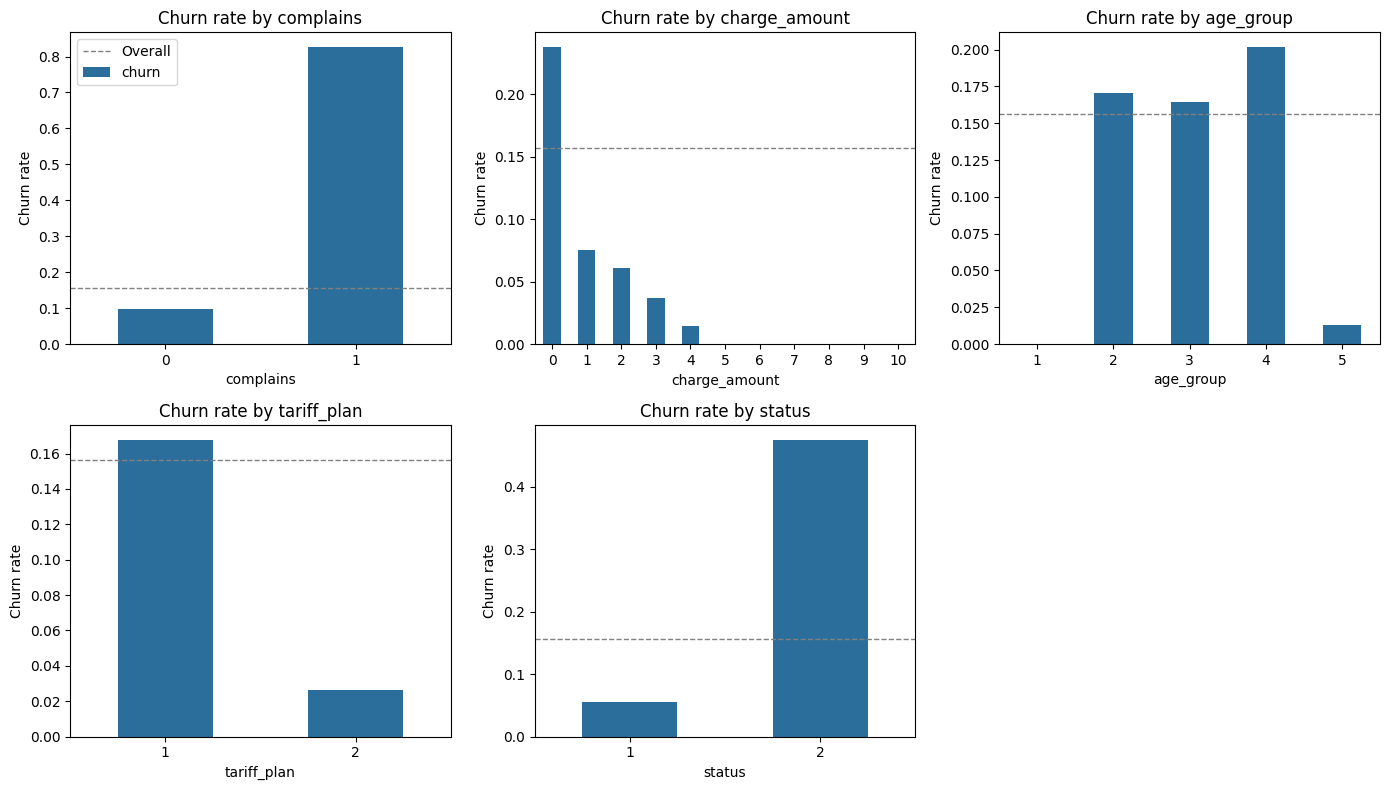

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, ax in zip(categorical_cols, axes.flatten()):
    df.groupby(col)["churn"].mean().plot(kind="bar", ax=ax, color="#2C6E9B")
    ax.axhline(df["churn"].mean(), color="gray", ls="--", lw=1, label="Overall")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=0)
axes[0, 0].legend()
axes[-1, -1].axis("off")
plt.tight_layout()
plt.savefig("../images/churn_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

churn,0,1
call_failure,7.7920,7.8587
subscription_length,32.5957,31.6839
seconds_of_use,5069.5882,1648.6614
frequency_of_use,77.8665,30.6973
frequency_of_sms,84.3536,16.8498
distinct_called_numbers,25.8723,13.0807
customer_value,538.5908,132.1757


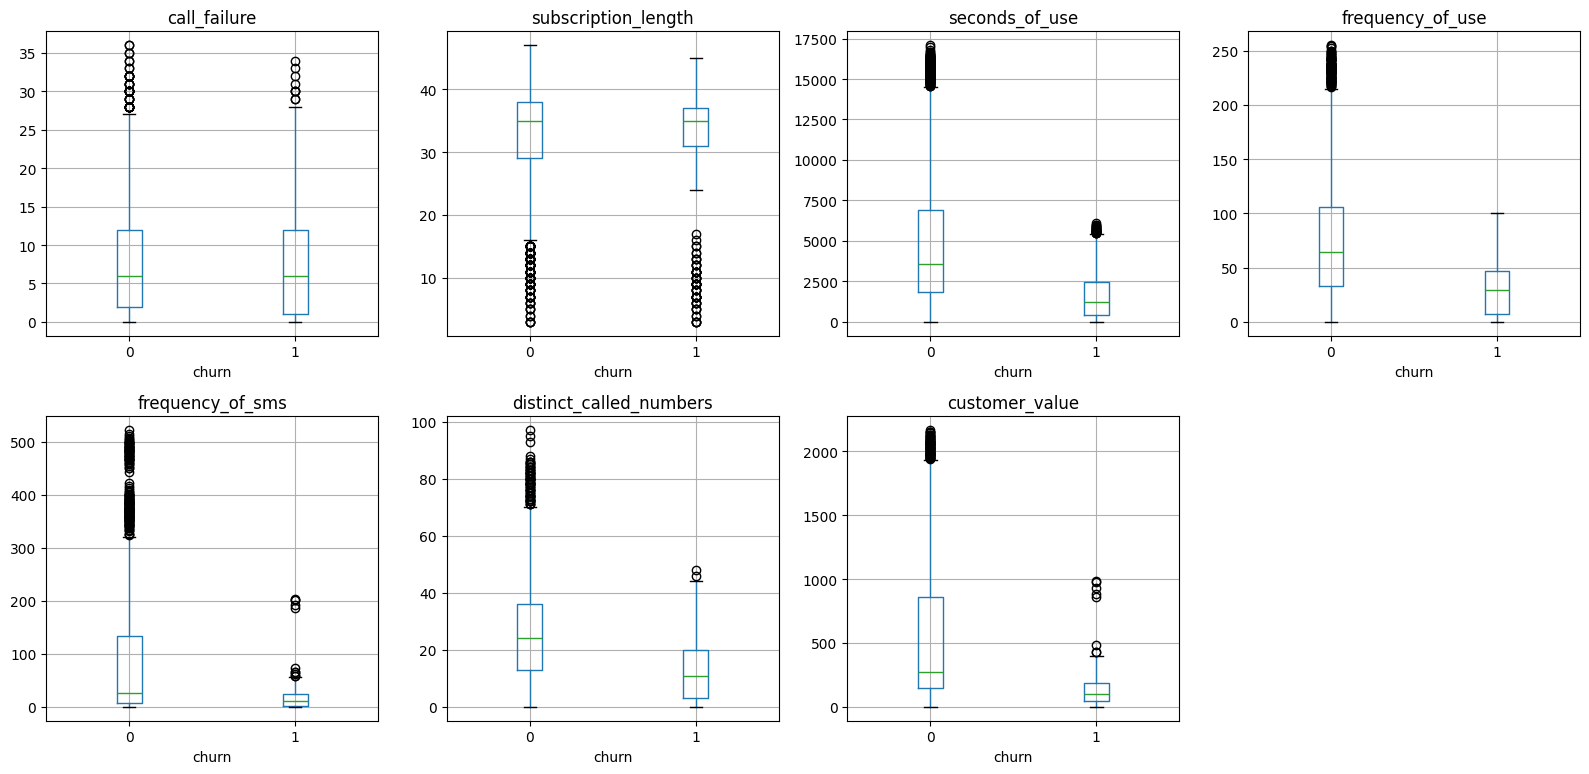

In [10]:
continuous_cols = ["call_failure", "subscription_length", "seconds_of_use", "frequency_of_use",
                   "frequency_of_sms", "distinct_called_numbers", "customer_value"]

display(df.groupby("churn")[continuous_cols].mean().T)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, ax in zip(continuous_cols, axes.flatten()):
    df.boxplot(column=col, by="churn", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("churn")
axes[-1, -1].axis("off")
plt.suptitle("")
plt.tight_layout()
plt.savefig("../images/usage_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
corr = df.corr(numeric_only=True)["churn"].drop("churn").sort_values()
display(corr.to_frame("corr_with_churn"))

# Highly correlated usage features
display(df[["seconds_of_use", "frequency_of_use", "frequency_of_sms",
            "distinct_called_numbers", "customer_value"]].corr().round(2))

,corr_with_churn
frequency_of_use,-0.2986
seconds_of_use,-0.2960
customer_value,-0.2871
distinct_called_numbers,-0.2703
frequency_of_sms,-0.2189
charge_amount,-0.2017
tariff_plan,-0.1060
subscription_length,-0.0380
age_group,-0.0059
call_failure,0.0033


,seconds_of_use,frequency_of_use,frequency_of_sms,distinct_called_numbers,customer_value
seconds_of_use,1.0000,0.9500,0.0900,0.6700,0.4100
frequency_of_use,0.9500,1.0000,0.0900,0.7300,0.3900
frequency_of_sms,0.0900,0.0900,1.0000,0.0700,0.9200
distinct_called_numbers,0.6700,0.7300,0.0700,1.0000,0.2800
customer_value,0.4100,0.3900,0.9200,0.2800,1.0000


In [12]:
# Churn by tenure quintile
tenure_bin = pd.qcut(df["subscription_length"], 5)
print(df.groupby(tenure_bin, observed=True)["churn"].agg(["mean", "count"]))

# Customers with no calls and no SMS
zero_use = (df["seconds_of_use"] == 0) & (df["frequency_of_sms"] == 0)
print(f"\nZero-usage customers: {zero_use.sum()}, churn rate: {df.loc[zero_use, 'churn'].mean():.1%}")

                      mean  count
subscription_length              
(2.999, 27.0]       0.1172    606
(27.0, 33.0]        0.1978    551
(33.0, 36.0]        0.2003    604
(36.0, 39.0]        0.1583    600
(39.0, 47.0]        0.1022    489

Zero-usage customers: 85, churn rate: 51.8%


**EDA findings**
- **Complaints** and **inactive status** are the strongest risk signals: customers who complained churn at
  83% vs 10% for those who did not; inactive customers churn at 48% vs 6% for active ones.
- **Pay-as-you-go** customers churn far more than contractual ones (17% vs 3%).
- Higher **charge amount** goes with lower churn; no customer with charge level ≥ 5 churned, but those groups
  are small, so this should not be read as "never churns".
- Churners have much lower **usage, SMS activity, contact diversity and customer value**.
- The raw number of **call failures** barely differs between groups; it is more informative relative to usage
  (a failure rate), which motivates the engineered features below.
- Usage features are highly correlated (seconds of use vs call frequency: 0.95; SMS frequency vs customer value: 0.92).

## 3. Feature Engineering
Ratio and intensity features normalize usage by activity level or tenure. All are computed row by row,
so they do not leak information across the train / test split.

In [13]:
def safe_ratio(num, den):
    return (num / den.replace(0, np.nan)).fillna(0)

df["avg_call_duration"] = safe_ratio(df["seconds_of_use"], df["frequency_of_use"])
df["sms_activity_share"] = safe_ratio(df["frequency_of_sms"], df["frequency_of_use"] + df["frequency_of_sms"])
df["use_per_month"] = safe_ratio(df["seconds_of_use"], df["subscription_length"])
df["calls_per_month"] = safe_ratio(df["frequency_of_use"], df["subscription_length"])
df["call_failure_rate"] = safe_ratio(df["call_failure"], df["frequency_of_use"])
df["contact_diversity"] = safe_ratio(df["distinct_called_numbers"], df["frequency_of_use"])

print(df.shape)

(2850, 19)


## 4. Train / Validation / Test Split
70 / 15 / 15, stratified on churn. Models are compared with 5-fold cross-validation on the training set;
the validation set is used to choose the decision threshold; the **test set is used once**, at the end.

In [14]:
X = df.drop(columns=["churn"])
y = df["churn"]

model_categorical = ["complains", "age_group", "tariff_plan", "status"]
model_numeric = [c for c in X.columns if c not in model_categorical]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

print("Train / Valid / Test:", X_train.shape[0], X_valid.shape[0], X_test.shape[0])
print("Churn rate:", round(y_train.mean(), 3), round(y_valid.mean(), 3), round(y_test.mean(), 3))

Train / Valid / Test: 1995 427 428
Churn rate: 0.156 0.157 0.157


## 5. Model Comparison
Three model families inside the same preprocessing pipeline (scaling for numeric features, one-hot encoding for
categorical ones): logistic regression as an interpretable baseline, random forest, and XGBoost.
Because churners are only 16% of customers, **PR-AUC** (average precision) is reported alongside ROC-AUC.

In [15]:
def make_preprocessor(numeric, categorical):
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
    ])

def make_pipeline(model, numeric=model_numeric, categorical=model_categorical):
    return Pipeline([("preprocessor", make_preprocessor(numeric, categorical)), ("model", model)])

candidates = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Logistic (balanced)": make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced",
                                                            random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "XGBoost": make_pipeline(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                           colsample_bytree=0.8, eval_metric="logloss",
                                           random_state=RANDOM_STATE, n_jobs=-1)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "precision": "precision", "recall": "recall", "f1": "f1"}

def cv_summary(models):
    rows = []
    for name, model in models.items():
        s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({"model": name,
                     "roc_auc": s["test_roc_auc"].mean(), "roc_auc_std": s["test_roc_auc"].std(),
                     "pr_auc": s["test_pr_auc"].mean(), "precision": s["test_precision"].mean(),
                     "recall": s["test_recall"].mean(), "f1": s["test_f1"].mean()})
    return pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)

cv_base = cv_summary(candidates)
cv_base

,roc_auc,roc_auc_std,pr_auc,precision,recall,f1
model,,,,,,
XGBoost,0.9879,0.0051,0.9477,0.9213,0.8403,0.8771
Random Forest,0.9854,0.0042,0.9316,0.9085,0.8144,0.8570
Logistic (balanced),0.9343,0.0109,0.7529,0.5007,0.8591,0.6324
Logistic Regression,0.9339,0.0112,0.7593,0.7768,0.5163,0.6188


Tree-based models clearly outperform logistic regression, especially on recall: logistic regression misses
about half of churners at the default 0.5 threshold, and class weighting raises recall only by sacrificing precision.
The non-linear interactions captured by trees (for example, complaints combined with low usage) matter here.

## 6. Hyperparameter Tuning (cross-validated on the training set)

In [16]:
rf_search = RandomizedSearchCV(
    candidates["Random Forest"],
    param_distributions={
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [4, 6, 8, 10, None],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", 0.5, 0.8],
        "model__class_weight": [None, "balanced"],
    },
    n_iter=25, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)

xgb_search = RandomizedSearchCV(
    candidates["XGBoost"],
    param_distributions={
        "model__n_estimators": [150, 250, 350, 500],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4, 5],
        "model__min_child_weight": [1, 3, 5],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.7, 0.8, 1.0],
        "model__reg_lambda": [1, 5, 10],
    },
    n_iter=20, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
xgb_search.fit(X_train, y_train)

print("RF best CV ROC-AUC: ", round(rf_search.best_score_, 4), rf_search.best_params_)
print("XGB best CV ROC-AUC:", round(xgb_search.best_score_, 4), xgb_search.best_params_)

RF best CV ROC-AUC:  0.9869 {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': None}
XGB best CV ROC-AUC: 0.9881 {'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 350, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}


In [17]:
cv_tuned = cv_summary({"Random Forest (tuned)": rf_search.best_estimator_,
                       "XGBoost (tuned)": xgb_search.best_estimator_})
cv_all = pd.concat([cv_base, cv_tuned]).sort_values("roc_auc", ascending=False)
display(cv_all)

final_name = cv_all.index[0]
final_model = {"Random Forest (tuned)": rf_search.best_estimator_,
               "XGBoost (tuned)": xgb_search.best_estimator_, **candidates}[final_name]
print("Selected model (highest CV ROC-AUC):", final_name)

,roc_auc,roc_auc_std,pr_auc,precision,recall,f1
model,,,,,,
XGBoost (tuned),0.9881,0.0050,0.9483,0.9217,0.8370,0.8762
XGBoost,0.9879,0.0051,0.9477,0.9213,0.8403,0.8771
Random Forest (tuned),0.9869,0.0037,0.9394,0.9162,0.8080,0.8572
Random Forest,0.9854,0.0042,0.9316,0.9085,0.8144,0.8570
Logistic (balanced),0.9343,0.0109,0.7529,0.5007,0.8591,0.6324
Logistic Regression,0.9339,0.0112,0.7593,0.7768,0.5163,0.6188


Selected model (highest CV ROC-AUC): XGBoost (tuned)


Tuning adds little: tuned XGBoost (CV ROC-AUC 0.988, PR-AUC 0.950) is essentially tied with default XGBoost
and slightly ahead of the tuned random forest (0.987 / 0.939). XGBoost is selected on cross-validation alone;
the test set has not been touched.

## 7. Validation: Threshold Selection
The selected model is fit on the training set and scored on the validation set. The default 0.5 cutoff is not
necessarily best for retention, where missing a churner usually costs more than an unnecessary offer,
so the threshold is chosen on validation by maximizing F1.

In [18]:
final_model.fit(X_train, y_train)
valid_prob = final_model.predict_proba(X_valid)[:, 1]
print("Validation ROC-AUC:", round(roc_auc_score(y_valid, valid_prob), 4))
print("Validation PR-AUC: ", round(average_precision_score(y_valid, valid_prob), 4))

rows = []
for thr in np.arange(0.10, 0.91, 0.05):
    pred = (valid_prob >= thr).astype(int)
    rows.append({"threshold": round(thr, 2),
                 "precision": precision_score(y_valid, pred, zero_division=0),
                 "recall": recall_score(y_valid, pred),
                 "f1": f1_score(y_valid, pred),
                 "customers_flagged": int(pred.sum())})
thr_table = pd.DataFrame(rows)
display(thr_table)

best_threshold = thr_table.loc[thr_table["f1"].idxmax(), "threshold"]
print("Selected threshold:", best_threshold)

Validation ROC-AUC: 0.9835
Validation PR-AUC:  0.9355


,threshold,precision,recall,f1,customers_flagged
0,0.1000,0.7381,0.9254,0.8212,84
1,0.1500,0.7722,0.9104,0.8356,79
2,0.2000,0.8219,0.8955,0.8571,73
3,0.2500,0.8429,0.8806,0.8613,70
4,0.3000,0.8551,0.8806,0.8676,69
5,0.3500,0.8657,0.8657,0.8657,67
6,0.4000,0.8788,0.8657,0.8722,66
7,0.4500,0.9062,0.8657,0.8855,64
8,0.5000,0.9032,0.8358,0.8682,62
9,0.5500,0.9000,0.8060,0.8504,60


Selected threshold: 0.45


The threshold of 0.45 is selected by maximizing F1
on the validation set.

At this threshold, the model flags 64 customers,
achieving 90.6% precision, 86.6% recall,
and an F1-score of 0.886.

In practice, the decision threshold should also
consider retention budgets and the relative costs
of missed churners and unnecessary outreach.

## 8. Feature Importance
Permutation importance on the validation set: how much ROC-AUC drops when each original feature is shuffled.
It is model-agnostic and works on the raw features rather than one-hot columns.

,feature,importance,std
1,complains,0.0444,0.0074
10,status,0.0264,0.0076
4,seconds_of_use,0.0203,0.0046
16,call_failure_rate,0.0141,0.0029
2,subscription_length,0.0139,0.0042
12,avg_call_duration,0.0114,0.0035
8,age_group,0.0085,0.0024
14,use_per_month,0.0067,0.0021
15,calls_per_month,0.0065,0.0016
5,frequency_of_use,0.0047,0.0020


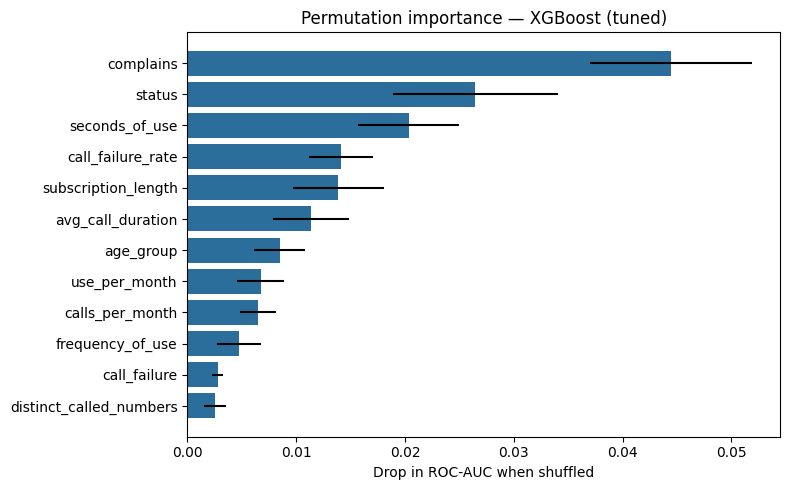

In [19]:
perm = permutation_importance(final_model, X_valid, y_valid, scoring="roc_auc",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": X_valid.columns,
                     "importance": perm.importances_mean, "std": perm.importances_std})
       .sort_values("importance", ascending=False))
display(imp.head(12))

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#2C6E9B")
ax.set_xlabel("Drop in ROC-AUC when shuffled")
ax.set_title(f"Permutation importance — {final_name}")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Complaints and inactive status dominate, followed by tenure, total usage and the engineered **call failure rate**
and **average call duration**. The raw call-failure count ranks near the bottom, which confirms the EDA point
that failures matter relative to usage.

**Robustness check: excluding `status`.** Inactive status is measured over the same period as usage and is
close to a symptom of churn. If it were unavailable in production, how much would performance drop?

In [20]:
from sklearn.base import clone

no_status = clone(final_model)
no_status.set_params(preprocessor=make_preprocessor(
    model_numeric, [c for c in model_categorical if c != "status"]))
s = cross_validate(no_status, X_train.drop(columns=["status"]), y_train, cv=cv,
                   scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=-1)
print(f"CV ROC-AUC without status: {s['test_roc_auc'].mean():.4f}  (with status: {cv_all.loc[final_name, 'roc_auc']:.4f})")
print(f"CV PR-AUC  without status: {s['test_pr_auc'].mean():.4f}  (with status: {cv_all.loc[final_name, 'pr_auc']:.4f})")

CV ROC-AUC without status: 0.9863  (with status: 0.9881)
CV PR-AUC  without status: 0.9424  (with status: 0.9483)


Without `status`, CV ROC-AUC falls only from 0.988 to 0.986 and PR-AUC from 0.950 to 0.940. The model does not
depend on this near-symptom feature; usage behaviour and complaints carry most of the signal.

## 9. Final Evaluation on the Test Set
The selected model is refit on train + validation and evaluated **once** on the untouched test set,
using the threshold chosen on validation.

In [21]:
X_dev = pd.concat([X_train, X_valid])
y_dev = pd.concat([y_train, y_valid])
final_model.fit(X_dev, y_dev)

test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

test_metrics = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, test_prob),
    "PR-AUC": average_precision_score(y_test, test_prob),
    "Precision": precision_score(y_test, test_pred),
    "Recall": recall_score(y_test, test_pred),
    "F1": f1_score(y_test, test_pred),
}, name=f"{final_name} @ threshold {best_threshold}")
display(test_metrics.to_frame())
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_pred))

,XGBoost (tuned) @ threshold 0.45
ROC-AUC,0.9920
PR-AUC,0.9615
Precision,0.8769
Recall,0.8507
F1,0.8636


Confusion matrix [[TN, FP], [FN, TP]]:
[[353   8]
 [ 10  57]]


On the held-out test set, the selected XGBoost model
achieves ROC-AUC 0.992 and PR-AUC 0.962.

At the validation-selected threshold of 0.45,
the model correctly identifies 57 of 67 churners,
with 8 false positives.

This corresponds to 87.7% precision, 85.1% recall,
and an F1-score of 0.864.

In [22]:
scores = X_test.copy()
scores["actual_churn"] = y_test.values
scores["churn_propensity"] = test_prob
scores["decile"] = pd.qcut(scores["churn_propensity"].rank(method="first", ascending=False),
                           10, labels=False) + 1   # decile 1 = highest risk

base_rate = scores["actual_churn"].mean()
decile_table = scores.groupby("decile").agg(
    customers=("actual_churn", "size"),
    churners=("actual_churn", "sum"),
    avg_propensity=("churn_propensity", "mean"),
    churn_rate=("actual_churn", "mean"))
decile_table["lift"] = decile_table["churn_rate"] / base_rate
decile_table["cumulative_capture"] = decile_table["churners"].cumsum() / scores["actual_churn"].sum()
decile_table

,customers,churners,avg_propensity,churn_rate,lift,cumulative_capture
decile,,,,,,
1,43,43,0.9655,1.0000,6.3881,0.6418
2,43,23,0.4661,0.5349,3.4169,0.9851
3,43,1,0.0705,0.0233,0.1486,1.0000
4,42,0,0.0173,0.0000,0.0000,1.0000
5,43,0,0.0054,0.0000,0.0000,1.0000
6,43,0,0.0022,0.0000,0.0000,1.0000
7,42,0,0.0011,0.0000,0.0000,1.0000
8,43,0,0.0005,0.0000,0.0000,1.0000
9,43,0,0.0003,0.0000,0.0000,1.0000


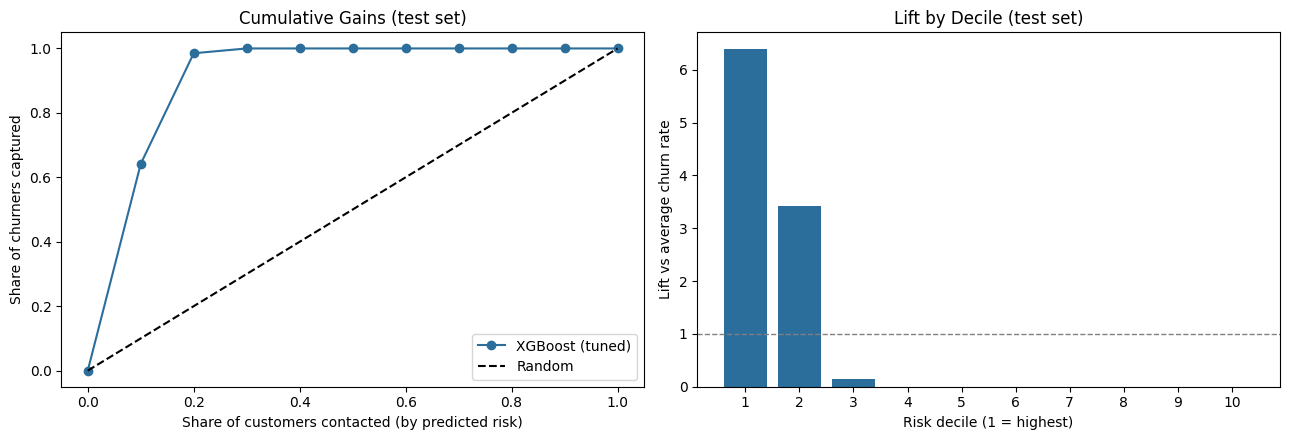

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

share = np.arange(0, 11) / 10
capture = np.concatenate([[0], decile_table["cumulative_capture"].values])
axes[0].plot(share, capture, "o-", color="#2C6E9B", label=final_name)
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("Share of customers contacted (by predicted risk)")
axes[0].set_ylabel("Share of churners captured")
axes[0].set_title("Cumulative Gains (test set)")
axes[0].legend()

axes[1].bar(decile_table.index, decile_table["lift"], color="#2C6E9B")
axes[1].axhline(1, color="gray", ls="--", lw=1)
axes[1].set_xticks(decile_table.index)
axes[1].set_xlabel("Risk decile (1 = highest)")
axes[1].set_ylabel("Lift vs average churn rate")
axes[1].set_title("Lift by Decile (test set)")

plt.tight_layout()
plt.savefig("../images/gains_lift.png", dpi=150, bbox_inches="tight")
plt.show()

Churn risk is highly concentrated. The top 10%
of customers ranked by predicted churn probability
account for 64.2% of observed churners.

The top 20% capture approximately 98.5% of churners
in the test set, demonstrating strong risk-ranking
performance.

These results describe predictive targeting, not
the causal impact of retention interventions.

## 10. Risk × Value Segmentation
Churn risk alone does not say how much to spend on retention. Combining predicted risk with the dataset's
`customer_value` score gives a simple targeting framework for the test-set customers.

In [24]:
scores["risk_tier"] = pd.cut(scores["decile"], bins=[0, 2, 5, 10],
                             labels=["High Risk", "Medium Risk", "Low Risk"])
scores["value_tier"] = pd.qcut(scores["customer_value"], q=3,
                               labels=["Low Value", "Medium Value", "High Value"])

display(pd.crosstab(scores["risk_tier"], scores["value_tier"], margins=True))
display(scores.pivot_table(index="risk_tier", columns="value_tier", values="actual_churn",
                           aggfunc="mean", observed=False).round(3))

value_tier,Low Value,Medium Value,High Value,All
risk_tier,,,,
High Risk,64,22,0,86
Medium Risk,61,60,7,128
Low Risk,18,60,136,214
All,143,142,143,428


value_tier,Low Value,Medium Value,High Value
risk_tier,,,
High Risk,0.7660,0.7730,NaN
Medium Risk,0.0160,0.0000,0.0000
Low Risk,0.0000,0.0000,0.0000


No high-risk customer is in the high-value tier: churners are concentrated among low- and medium-value
customers, consistent with the EDA finding that churners use the service far less. High-value customers
are almost all low risk, which points to loyalty and upsell programs rather than retention discounts for them.

In [25]:
def assign_action(row):
    if row["risk_tier"] == "High Risk" and row["value_tier"] != "Low Value":
        return "Priority retention offer"
    if row["risk_tier"] == "High Risk":
        return "Low-cost retention (e.g. SMS / app nudge)"
    if row["risk_tier"] == "Medium Risk":
        return "Monitor + service follow-up"
    if row["value_tier"] == "High Value":
        return "Loyalty / upsell"
    return "No action"

scores["action"] = scores.apply(assign_action, axis=1)
scores.groupby("action").agg(customers=("actual_churn", "size"),
                             churn_rate=("actual_churn", "mean"),
                             avg_value=("customer_value", "mean")).sort_values("churn_rate", ascending=False)

,customers,churn_rate,avg_value
action,,,
Priority retention offer,22,0.7727,240.8093
Low-cost retention (e.g. SMS / app nudge),64,0.7656,72.8515
Monitor + service follow-up,128,0.0078,214.6118
Loyalty / upsell,136,0.0000,1117.9899
No action,78,0.0000,220.3731


## Summary
- **Data:** 3,150 subscribers, 300 exact duplicates removed (2,850 kept), 16% churn rate.
- **Drivers:** complaints (83% churn vs 10%), inactive status, pay-as-you-go plans and low usage are the strongest
  signals; engineered ratios such as call failure rate add information that raw counts miss.
- **Model:** Tuned XGBoost was selected using 5-fold
  cross-validation. The decision threshold of 0.45
  was selected on the validation set.

- **Test performance:** ROC-AUC 0.992, PR-AUC 0.962,
  precision 87.7%, recall 85.1%, and F1 0.864.

- **Business use:** The top 20% of customers ranked
  by churn risk contain approximately 98.5% of
  observed churners in the test set. Risk and value
  segmentation can inform retention prioritization,
  but intervention effectiveness requires separate
  experimental validation.

**Limitations**
- Performance is very high because a few features (complaints, inactive status) are strong and close in time to
  churn; in production, features should be measured well before the churn window to keep lead time for outreach.
- The data is a single snapshot from one operator; scores should be validated over time.
- A propensity model ranks who is *likely to churn*, not who can be *saved* by an offer. Measuring which customers
  respond to retention offers requires an experiment and an uplift model.